# 05 · Torneo de modelos — AccessGuard AI (marco Zero Trust / IGA)

**Objetivo:** elegir **dos finalistas** con evidencia, sin tocar la reserva ni `test.csv`, juzgándolos con el **marco de seguridad** del proyecto y no con dólares:

| Métrica de éxito | Cómo se mide aquí |
|---|---|
| **Tasa de Auto-Aprobación Segura** | % de solicitudes que el modelo aprueba solo **sin ningún acceso indebido** (FPR = 0 %) y, en la variante práctica, las que puntúan con confianza ≥ 98 % |
| **Reducción de fricción / SLA** | Latencia medida de la decisión (ms por solicitud) |
| **Triaje asistido (human-in-the-loop)** | Lo que no se auto-aprueba va a un analista IAM: carga de revisión y "riqueza" de esa cola en denegaciones (*lift*) |

Y las métricas técnicas de siempre: **ROC-AUC**, **PR-AUC** de la clase *denegar* y **precisión en zonas de ultra-alta confianza** (donde el modelo se atreve a aprobar solo).

Reglas del torneo:
1. **Mismos datos y misma validación para todos:** 5 pliegues `StratifiedGroupKFold` — estratificados por `ACTION` (desbalance 94/6) **y agrupados por `MGR_ID`**: un mismo gerente nunca está en entrenamiento y validación.
2. **Un punto de referencia (baseline):** regresión logística L2.
3. **Mirar la variabilidad entre pliegues**, no solo el promedio.
4. Las variables (notebook 04) se calculan **dentro de cada pliegue**, solo con su entrenamiento.

**Regularización de los modelos de árboles** (`build_model` en `src/accessguard/modeling.py`): profundidad 4, tasa de aprendizaje 0,03, `subsample=0.7` y penalización L2 / mínimo de peso por hoja (`reg_lambda=10`, `min_child_weight`/`min_child_samples`, `l2_leaf_reg=10`).

> **Convención:** clase positiva = 1 = *aprobar*; un **falso positivo es un acceso indebido concedido** (el error que el marco Zero Trust no tolera).
> La clase *denegar* (5,8 %) es la minoritaria: se reporta su PR-AUC. Nunca se usa accuracy sola.

In [1]:
import sys, warnings, json, time
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config.settings import PROCESSED_DIR, REPORTS_DIR, SEED, TARGET, GROUP_COL, AUTO_APPROVE_CONFIDENCE, CONFIDENCE_BANDS
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Datos y pliegues

Solo `train_clean.csv`. La reserva (`holdout`) y `test.csv` no se leen en este notebook.

In [2]:
from accessguard.modeling import MODEL_NAMES, build_model, build_pipeline, fold_matrices, make_cv, metrics_at
from accessguard.security_metrics import (auto_approval_at_confidence, auto_approval_at_zero_fpr, decision_latency_ms,
                                          fpr_upper_bound, precision_at_top, review_queue_stats)

train = pd.read_csv(PROCESSED_DIR / "train_clean.csv")
y = train[TARGET].to_numpy()
X = train.drop(columns=TARGET)
cv = make_cv(5, SEED)

seen = []
for k, (tr, va) in enumerate(cv.split(X, y, groups=X[GROUP_COL])):
    assert not set(X[GROUP_COL].iloc[tr]) & set(X[GROUP_COL].iloc[va]), "fuga por gerente"
    seen.append({"pliegue": k, "filas val": len(va), "gerentes val": X[GROUP_COL].iloc[va].nunique(), "% denegar (val)": 100 * (1 - y[va].mean())})
print("Sin gerentes compartidos entre entrenamiento y validación en los 5 pliegues.")
pd.DataFrame(seen).round(2)

Sin gerentes compartidos entre entrenamiento y validación en los 5 pliegues.


,pliegue,filas val,gerentes val,% denegar (val)
0,0,5243,674,5.78
1,1,5239,662,5.80
2,2,5247,672,5.81
3,3,5243,671,5.78
4,4,5243,681,5.78


In [3]:
t0 = time.time()
folds = fold_matrices(X, y, X[GROUP_COL], cv, seed=SEED)      # variables de cada pliegue, calculadas una vez
print(f"{len(folds)} pliegues · {folds[0][0].shape[1]} variables · {time.time() - t0:.1f} s")

5 pliegues · 29 variables · 5.9 s


## 2. Correr el torneo

Cada modelo se entrena con el entrenamiento de cada pliegue y predice la probabilidad de *aprobar* en el pliegue de validación.
Se guardan las **predicciones fuera de pliegue (OOF)** de todas las filas y las métricas de **cada pliegue**, incluida la auto-aprobación con FPR = 0 % por pliegue.

In [4]:
fold_rows, oof = [], {}
for name in MODEL_NAMES:
    p_oof = np.zeros(len(y)); t0 = time.time()
    for k, (X_tr, y_tr, X_va, y_va, idx_va) in enumerate(folds):
        model = build_model(name, seed=SEED).fit(X_tr, y_tr)
        p = model.predict_proba(X_va)[:, 1]
        p_oof[idx_va] = p
        m = metrics_at(y_va, p, 0.5)
        fold_rows.append({"modelo": name, "pliegue": k, "roc_auc": m["roc_auc"], "pr_auc_deny": m["pr_auc_deny"], "pr_auc_approve": m["pr_auc_approve"],
                          "aar_fpr0": auto_approval_at_zero_fpr(y_va, p)["auto_approval_rate"]})
    oof[name] = p_oof
    print(f"{name:24s} listo en {time.time() - t0:5.1f} s")
fold_df = pd.DataFrame(fold_rows)

LogReg L2 (baseline)     listo en   0.2 s


LogReg ElasticNet        listo en   2.9 s


Random Forest            listo en   5.7 s


XGBoost                  listo en   1.8 s


LightGBM                 listo en   1.3 s


CatBoost                 listo en   8.2 s


## 3. Métricas de ranking: ROC-AUC y PR-AUC (media ± desviación entre pliegues)

ROC-AUC y PR-AUC miden qué tan bien **ordena** el modelo las solicitudes (de "claramente legítima" a "claramente indebida"), sin depender de ningún umbral.

In [5]:
g = fold_df.groupby("modelo")
rank_tbl = pd.DataFrame({
    "ROC-AUC": g.roc_auc.mean(), "± ROC": g.roc_auc.std(),
    "PR-AUC denegar": g.pr_auc_deny.mean(), "± PR": g.pr_auc_deny.std(),
    "PR-AUC aprobar": g.pr_auc_approve.mean(),
})
print("Referencia azar: ROC-AUC = 0.5 · PR-AUC denegar = tasa de 'denegar' =", round(1 - y.mean(), 4))
rank_tbl.sort_values("ROC-AUC", ascending=False).round(4)

Referencia azar: ROC-AUC = 0.5 · PR-AUC denegar = tasa de 'denegar' = 0.0579


,ROC-AUC,± ROC,PR-AUC denegar,± PR,PR-AUC aprobar
modelo,,,,,
LogReg ElasticNet,0.7331,0.0080,0.1849,0.0154,0.9755
LogReg L2 (baseline),0.7330,0.0085,0.1850,0.0156,0.9755
Random Forest,0.7257,0.0165,0.1955,0.0306,0.9744
LightGBM,0.7234,0.0257,0.1870,0.0248,0.9741
XGBoost,0.7204,0.0271,0.1868,0.0311,0.9737
CatBoost,0.7190,0.0263,0.1871,0.0255,0.9738


## 4. Zonas de ultra-alta confianza: la auto-aprobación segura

Aquí está el corazón del marco Zero Trust. El modelo solo debe aprobar **sin humano** lo que puntúa por encima de todo lo que podía ser indebido.

* **Auto-aprobación @ FPR = 0 %** (estricta): se aprueba únicamente lo que puntúa **por encima de la solicitud indebida mejor puntuada** de las predicciones OOF. Cero accesos indebidos *en esta muestra*.
  Observar 0 errores no prueba que la tasa real sea 0: se reporta la **cota superior del FPR al 95 %** (≈ 3 / nº de negativos).
* **Auto-aprobación @ confianza ≥ 98 %** (práctica): se aprueba lo que el modelo puntúa con p ≥ 0,98; se cuenta **cuántos accesos indebidos se cuelan** y la precisión de esa zona.
* **Precisión en el top-k %**: de las solicitudes con mayor probabilidad, ¿qué fracción era realmente legítima? (la base es 94,2 %).

Se calcula sobre las predicciones OOF de todas las filas (cada una predicha por un modelo que no vio a su gerente).

In [6]:
n_neg = int((y == 0).sum())
rows = []
for name in MODEL_NAMES:
    z = auto_approval_at_zero_fpr(y, oof[name])
    c = auto_approval_at_confidence(y, oof[name], AUTO_APPROVE_CONFIDENCE)
    rows.append({
        "modelo": name,
        "AAR @ FPR=0 %": z["auto_approval_rate"], "umbral (FPR=0)": z["threshold"],
        "AAR @ FPR=0 por pliegue (media)": fold_df.loc[fold_df.modelo == name, "aar_fpr0"].mean(),
        "FPR real ≤ (95 %)": z["fpr_upper95"],
        f"AAR @ p≥{AUTO_APPROVE_CONFIDENCE:.2f}": c["auto_approval_rate"], "FP colados": c["fp"], "precisión de la zona": c["precision"],
        "FPR @ confianza": c["fpr"],
        "precisión top 5 %": precision_at_top(y, oof[name], 0.05), "precisión top 10 %": precision_at_top(y, oof[name], 0.10),
    })
sec = pd.DataFrame(rows).set_index("modelo")
print(f"Negativos (solicitudes que debían denegarse): {n_neg:,} · precisión base de 'aprobar': {y.mean():.3%}")
sec.round(4)

Negativos (solicitudes que debían denegarse): 1,518 · precisión base de 'aprobar': 94.209%


,AAR @ FPR=0 %,umbral (FPR=0),AAR @ FPR=0 por pliegue (media),FPR real ≤ (95 %),AAR @ p≥0.98,FP colados,precisión de la zona,FPR @ confianza,precisión top 5 %,precisión top 10 %
modelo,,,,,,,,,,
LogReg L2 (baseline),0.0203,0.9906,0.0370,0.002,0.0696,17,0.9907,0.0112,0.9931,0.9893
LogReg ElasticNet,0.0204,0.9902,0.0387,0.002,0.0645,13,0.9923,0.0086,0.9939,0.9893
Random Forest,0.0071,0.9802,0.0257,0.002,0.0074,1,0.9949,0.0007,0.9886,0.9882
XGBoost,0.0185,0.9935,0.0298,0.002,0.2187,92,0.9840,0.0606,0.9908,0.9874
LightGBM,0.0077,0.9950,0.0267,0.002,0.2252,98,0.9834,0.0646,0.9947,0.9882
CatBoost,0.0069,0.9933,0.0227,0.002,0.1479,51,0.9868,0.0336,0.9908,0.9893


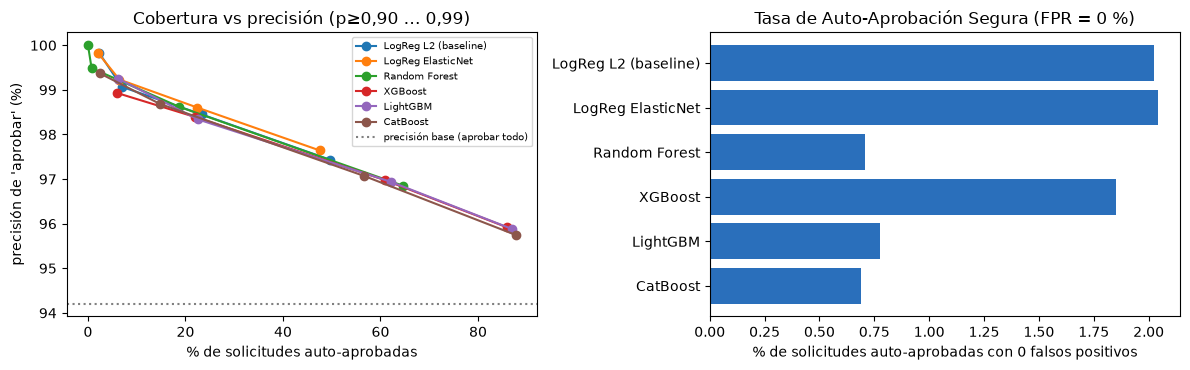

,confianza ≥,% auto-aprobado,n,FP,precisión
modelo,,,,,
LogReg L2 (baseline),0.98,0.0696,1824,17,0.9907
LogReg ElasticNet,0.98,0.0645,1691,13,0.9923
Random Forest,0.98,0.0074,195,1,0.9949
XGBoost,0.98,0.2187,5734,92,0.9840
LightGBM,0.98,0.2252,5903,98,0.9834
CatBoost,0.98,0.1479,3876,51,0.9868


In [7]:
bands = []
for name in MODEL_NAMES:
    for b in CONFIDENCE_BANDS:
        r = auto_approval_at_confidence(y, oof[name], b)
        bands.append({"modelo": name, "confianza ≥": b, "% auto-aprobado": r["auto_approval_rate"], "n": r["n_approved"], "FP": r["fp"], "precisión": r["precision"]})
bands = pd.DataFrame(bands)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name in MODEL_NAMES:
    sub = bands[bands.modelo == name]
    axes[0].plot(sub["% auto-aprobado"] * 100, sub["precisión"] * 100, "o-", label=name)
axes[0].axhline(y.mean() * 100, color="grey", ls=":", label="precisión base (aprobar todo)")
axes[0].set_xlabel("% de solicitudes auto-aprobadas"); axes[0].set_ylabel("precisión de 'aprobar' (%)"); axes[0].set_title("Cobertura vs precisión (p≥0,90 … 0,99)"); axes[0].legend(fontsize=7)
axes[1].barh(sec.index, sec["AAR @ FPR=0 %"] * 100, color="#2A6FBB"); axes[1].invert_yaxis()
axes[1].set_xlabel("% de solicitudes auto-aprobadas con 0 falsos positivos"); axes[1].set_title("Tasa de Auto-Aprobación Segura (FPR = 0 %)")
plt.tight_layout(); plt.show()
bands[bands["confianza ≥"] == AUTO_APPROVE_CONFIDENCE].set_index("modelo").round(4)

**Cómo leerlo.**

* La **Tasa de Auto-Aprobación Segura (FPR = 0 %) es baja** (del orden de 1 – 2 % de las solicitudes). Con 6 códigos anónimos y gerentes nuevos, el modelo casi nunca puede *garantizar* que una solicitud sea legítima: **la mayoría debe ir a revisión humana**. Es un resultado honesto, no un fallo.
* **No compares la columna "por pliegue" con la OOF:** cada pliegue tiene ~300 negativos (no 1.518), así que su umbral de FPR = 0 % es menos exigente y la tasa sale más alta (≈ 2 – 4 %). La cifra de referencia es la OOF (1.518 negativos).
* **La confianza ≥ 98 % no equivale a FPR = 0 %**: esa zona es más grande, pero deja pasar algunos accesos indebidos (columna "FP colados"). La probabilidad del modelo no está calibrada perfectamente en esa cola; no debe leerse como garantía.
* Los modelos que **más auto-aprueban a p ≥ 0,98 no son los más seguros**: auto-aprobar más con peor precisión es más riesgo, no más valor. Por eso la auto-aprobación estricta (FPR = 0 %) pesa más en la selección que la cobertura a 0,98.

## 5. Triaje asistido (human-in-the-loop) y fricción

Todo lo que no se auto-aprueba va a la cola de un analista IAM. Si la cola es solo "todo", hay **fatiga de aprobación** (el analista aprueba por inercia). La cola ayuda si está **enriquecida en denegaciones**
(*lift* = tasa de denegaciones en la cola ÷ tasa global de 5,8 %) y si es más corta que revisar todo. Política evaluada: *p por encima del umbral estricto de FPR = 0 % → auto-aprobar; el resto → analista* (no se deniega automáticamente nada: la denegación es una decisión de mayor impacto y debe poder apelarse).

In [8]:
rows = []
for name in MODEL_NAMES:
    z = auto_approval_at_zero_fpr(y, oof[name])
    q = review_queue_stats(y, oof[name], z["threshold"] + 1e-12)       # cola = lo que no supera el umbral estricto
    rows.append({"modelo": name, "% a revisión humana": q["review_rate"], "carga evitada vs revisar todo": 1 - q["review_rate"],
                 "% denegación en la cola": q["deny_rate_in_queue"], "lift de la cola": q["lift"],
                 "% de denegaciones que pasan por humano": q["share_of_denials_in_queue"]})
triage = pd.DataFrame(rows).set_index("modelo")
triage.round(4)

,% a revisión humana,carga evitada vs revisar todo,% denegación en la cola,lift de la cola,% de denegaciones que pasan por humano
modelo,,,,,
LogReg L2 (baseline),0.9797,0.0203,0.0591,1.0207,1.0
LogReg ElasticNet,0.9796,0.0204,0.0591,1.0208,1.0
Random Forest,0.9929,0.0071,0.0583,1.0071,1.0
XGBoost,0.9815,0.0185,0.0590,1.0188,1.0
LightGBM,0.9923,0.0077,0.0584,1.0078,1.0
CatBoost,0.9931,0.0069,0.0583,1.0070,1.0


**Lectura.** Con el umbral estricto el 100 % de las solicitudes indebidas (por construcción) pasa por un analista, pero la cola apenas es más corta que "revisar todo" y su *lift* ≈ 1: **el modelo, por sí solo, no prioriza la cola**.
La reducción real de fricción solo llegará (a) ampliando la zona segura con mejores datos/variables, (b) con una **política por criticidad del recurso** (recursos de bajo impacto con umbral menos estricto) o (c) **ordenando la cola por puntuación** para que el analista vea primero lo más dudoso.

### Latencia de decisión (SLA)

El tiempo de espera manual actual **no está en los datos**; hay que medirlo con los tickets del área IAM. Lo que sí se mide aquí es la latencia del modelo, entrenado con todo el entrenamiento:

In [9]:
lat = {}
for name in MODEL_NAMES:
    pipe = build_pipeline(name, None, seed=SEED).fit(X, y)
    lat[name] = decision_latency_ms(pipe, X, repeats=60)
latency = pd.DataFrame(lat).T.rename(columns={"single_median_ms": "mediana 1 solicitud (ms)", "single_p95_ms": "p95 1 solicitud (ms)", "batch_ms_per_request": "ms/solicitud en lote de 1.000"})
latency.round(2)

,mediana 1 solicitud (ms),p95 1 solicitud (ms),ms/solicitud en lote de 1.000
LogReg L2 (baseline),10.39,10.56,0.02
LogReg ElasticNet,10.38,10.71,0.02
Random Forest,48.70,50.47,0.07
XGBoost,13.26,14.49,0.03
LightGBM,12.60,13.87,0.03
CatBoost,10.79,11.66,0.02


## 6. Matriz de confusión en el punto de operación seguro

En el umbral estricto (FPR = 0 %): *auto-aprobar* o *a revisión humana*. La celda "real denegar / auto-aprobar" es **0 por construcción**.

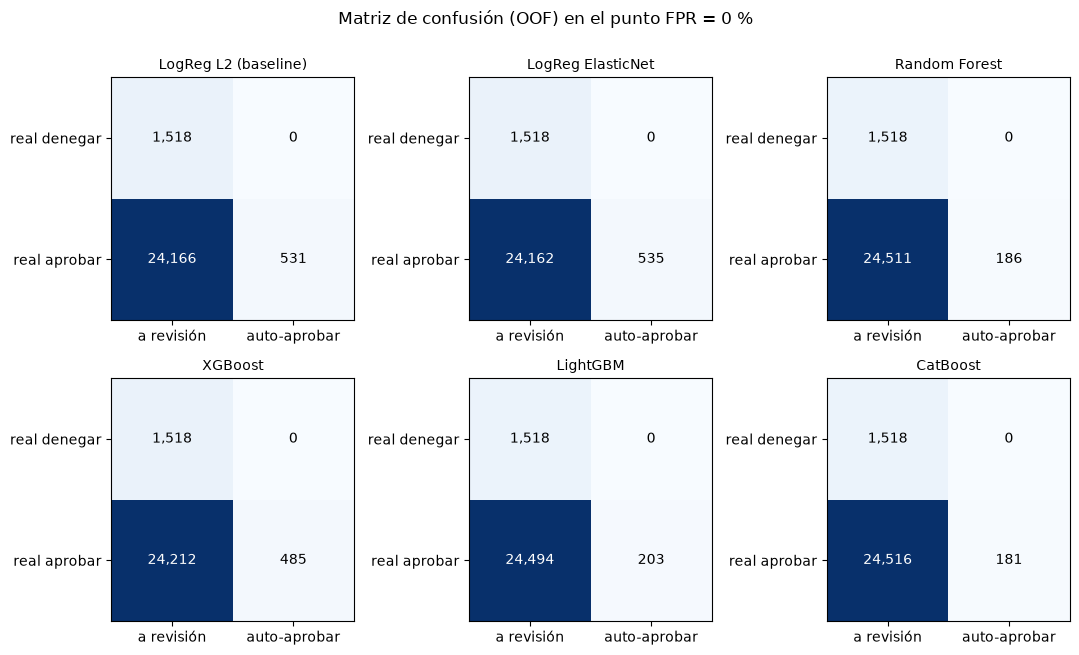

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, name in zip(axes.ravel(), MODEL_NAMES):
    z = auto_approval_at_zero_fpr(y, oof[name]); ap = oof[name] > z["threshold"]
    cm = np.array([[((~ap) & (y == 0)).sum(), (ap & (y == 0)).sum()], [((~ap) & (y == 1)).sum(), (ap & (y == 1)).sum()]])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["a revisión", "auto-aprobar"]); ax.set_yticks([0, 1], ["real denegar", "real aprobar"]); ax.set_title(name, fontsize=10)
plt.suptitle("Matriz de confusión (OOF) en el punto FPR = 0 %", y=1.0); plt.tight_layout(); plt.show()

## 7. F1 y recall de *denegar* (referencia técnica)

Complemento técnico a umbral 0,5 y al umbral de F1 máximo. Ninguno es el punto de operación del proyecto (que es el estricto de la sección 4), pero permite comparar con la literatura.

In [11]:
from accessguard.modeling import f1_curve
rows = []
for name in MODEL_NAMES:
    prec, rec, f1, thr = f1_curve(y, oof[name])
    i = int(np.nanargmax(f1[:-1])); t_f1 = 1 - thr[i]
    for label, t in [("0.5", 0.5), ("máx. F1 denegar", t_f1)]:
        mm = metrics_at(y, oof[name], t)
        rows.append({"modelo": name, "umbral": label, "valor": round(t, 3), "F1 denegar": mm["f1_deny"], "recall denegar": mm["recall_deny"], "F1 aprobar": mm["f1_approve"], "recall aprobar": mm["recall_approve"]})
pd.DataFrame(rows).round(4)

,modelo,umbral,valor,F1 denegar,recall denegar,F1 aprobar,recall aprobar
0,LogReg L2 (baseline),0.5,0.500,0.1493,0.0955,0.9673,0.9887
1,LogReg L2 (baseline),máx. F1 denegar,0.762,0.2326,0.3386,0.9293,0.9033
2,LogReg ElasticNet,0.5,0.500,0.1510,0.0975,0.9670,0.9881
3,LogReg ElasticNet,máx. F1 denegar,0.740,0.2339,0.3090,0.9366,0.9181
4,Random Forest,0.5,0.500,0.0156,0.0079,0.9703,0.9998
5,Random Forest,máx. F1 denegar,0.820,0.2502,0.2931,0.9454,0.9355
6,XGBoost,0.5,0.500,0.0257,0.0132,0.9702,0.9994
7,XGBoost,máx. F1 denegar,0.832,0.2484,0.2431,0.9549,0.9561
8,LightGBM,0.5,0.500,0.0207,0.0105,0.9702,0.9995
9,LightGBM,máx. F1 denegar,0.851,0.2492,0.2556,0.9526,0.9511


## 8. ¿La diferencia entre los mejores es real?

Los modelos se evaluaron **en los mismos pliegues**, así que se comparan de a pares: diferencia de ROC-AUC pliegue a pliegue entre el líder y el resto.

In [12]:
summary = rank_tbl.join(sec[["AAR @ FPR=0 %", f"AAR @ p≥{AUTO_APPROVE_CONFIDENCE:.2f}", "FP colados", "precisión de la zona"]])
summary["rank ROC"] = summary["ROC-AUC"].rank(ascending=False)
summary["rank PR"] = summary["PR-AUC denegar"].rank(ascending=False)
summary["rank zona segura"] = summary["AAR @ FPR=0 %"].rank(ascending=False)
summary["rank medio"] = summary[["rank ROC", "rank PR", "rank zona segura"]].mean(axis=1)
summary = summary.sort_values(["rank medio", "ROC-AUC"], ascending=[True, False])
summary["finalista"] = ["★" if i < 2 else "" for i in range(len(summary))]
order = list(summary.index); top = order[:2]

wide = fold_df.pivot(index="pliegue", columns="modelo", values="roc_auc")
rows = []
for other in order[1:]:
    d = wide[order[0]] - wide[other]
    rows.append({"líder": order[0], "contra": other, "dif. media ROC-AUC": d.mean(), "pliegues que gana": f"{(d > 0).sum()} de {len(d)}",
                 "dif. / desv. entre pliegues": d.mean() / d.std(ddof=1) if d.std(ddof=1) > 0 else np.inf})
pd.DataFrame(rows).round(4)

,líder,contra,dif. media ROC-AUC,pliegues que gana,dif. / desv. entre pliegues
0,LogReg ElasticNet,LogReg L2 (baseline),0.0001,3 de 5,0.1231
1,LogReg ElasticNet,Random Forest,0.0074,3 de 5,0.4135
2,LogReg ElasticNet,LightGBM,0.0097,3 de 5,0.3927
3,LogReg ElasticNet,XGBoost,0.0127,3 de 5,0.4732
4,LogReg ElasticNet,CatBoost,0.0142,3 de 5,0.5462


Una diferencia que **gana en los 5 pliegues** y es varias veces mayor que su desviación es consistente; si gana en 3 de 5 y la razón es < 1, es un **empate práctico**.

## 9. Finalistas y registro de resultados

**Criterio de selección:** posición media en tres métricas — **ROC-AUC**, **PR-AUC de *denegar*** y **Tasa de Auto-Aprobación Segura (FPR = 0 %)** (la medida de la "zona de ultra-alta confianza") —, con desempate por ROC-AUC.

In [13]:
finalists = list(summary.index[:2])
summary.to_csv(REPORTS_DIR / "05_torneo_tabla.csv")
sec.to_csv(REPORTS_DIR / "05_zonas_alta_confianza.csv")
triage.to_csv(REPORTS_DIR / "05_triaje_asistido.csv")
latency.to_csv(REPORTS_DIR / "05_latencia_decision.csv")
bands.to_csv(REPORTS_DIR / "05_bandas_confianza.csv", index=False)
(REPORTS_DIR / "05_finalistas.json").write_text(json.dumps({
    "criterio": "posición media en ROC-AUC, PR-AUC (denegar) y Tasa de Auto-Aprobación Segura (FPR=0), 5 pliegues StratifiedGroupKFold por MGR_ID; desempate por ROC-AUC",
    "marco": "Zero Trust / IGA: éxito = auto-aprobación segura, reducción de fricción (SLA) y triaje asistido",
    "finalistas": finalists, "mejor": finalists[0], "seed": SEED, "n_splits": 5,
    "roc_auc": {n: float(summary.loc[n, "ROC-AUC"]) for n in summary.index},
    "pr_auc_deny": {n: float(summary.loc[n, "PR-AUC denegar"]) for n in summary.index},
    "auto_approval_rate_fpr0": {n: float(summary.loc[n, "AAR @ FPR=0 %"]) for n in summary.index},
}, indent=2, ensure_ascii=False), encoding="utf-8")
print("Finalistas:", finalists)
summary.round(4)

Finalistas: ['LogReg ElasticNet', 'LogReg L2 (baseline)']


,ROC-AUC,± ROC,PR-AUC denegar,± PR,PR-AUC aprobar,AAR @ FPR=0 %,AAR @ p≥0.98,FP colados,precisión de la zona,rank ROC,rank PR,rank zona segura,rank medio,finalista
modelo,,,,,,,,,,,,,,
LogReg ElasticNet,0.7331,0.0080,0.1849,0.0154,0.9755,0.0204,0.0645,13,0.9923,1.0,6.0,1.0,2.6667,★
LogReg L2 (baseline),0.7330,0.0085,0.1850,0.0156,0.9755,0.0203,0.0696,17,0.9907,2.0,5.0,2.0,3.0000,★
Random Forest,0.7257,0.0165,0.1955,0.0306,0.9744,0.0071,0.0074,1,0.9949,3.0,1.0,5.0,3.0000,
LightGBM,0.7234,0.0257,0.1870,0.0248,0.9741,0.0077,0.2252,98,0.9834,4.0,3.0,4.0,3.6667,
XGBoost,0.7204,0.0271,0.1868,0.0311,0.9737,0.0185,0.2187,92,0.9840,5.0,4.0,3.0,4.0000,
CatBoost,0.7190,0.0263,0.1871,0.0255,0.9738,0.0069,0.1479,51,0.9868,6.0,2.0,6.0,4.6667,


## 10. Decisión y lectura honesta de los resultados

Los números de las secciones 3 a 9 son la evidencia. Lo que conviene tener presente (se contrasta con las tablas en cada ejecución):

* **El techo de ranking es modesto:** ROC-AUC ≈ 0,70–0,73 y PR-AUC de *denegar* ≈ 0,17–0,20 (azar 0,058). Con códigos anónimos y gerentes nuevos el modelo ordena mejor que el azar, pero **no es un detector fiable de accesos indebidos**.
* **La auto-aprobación segura es pequeña (≈ 1 – 2 %).** El marco Zero Trust exige no conceder accesos indebidos: con esa restricción, el modelo solo puede resolver solo una fracción mínima de las solicitudes. La mayor parte va a un analista IAM (*human-in-the-loop*).
* **Más cobertura a p ≥ 0,98 no es mejor:** los modelos que auto-aprueban más en esa zona dejan pasar más accesos indebidos. Ninguno es seguro para auto-aprobar a ese umbral sin un control adicional.
* **La cola de revisión no está enriquecida** (lift ≈ 1 con el umbral estricto): para reducir la fatiga de aprobación hay que ordenar la cola por riesgo y/o aplicar umbrales por criticidad del recurso (información que el dataset no trae).
* **La latencia del modelo es de milisegundos** (sección 5), pero la comparación con el tiempo de espera manual actual **necesita datos reales de tickets**: no está en este dataset y no se inventa.
* **Empates:** las diferencias entre varios modelos son menores que la desviación entre pliegues (sección 8): el torneo elige finalistas, no un campeón definitivo.
* La **evaluación final con la reserva cerrada** queda pendiente para la etapa de validación, con el modelo y el umbral ya fijados. Se evaluó una vez con el enfoque monetario anterior (notebook 06); esa cifra no vale para este marco.

> **Pendiente:** el notebook 06 (Optuna) todavía optimiza con la política monetaria anterior y **no se ha reorientado** a este marco; sus resultados previos (`reports/06_*`) son del enfoque de costos.